**Imports**

In [1]:
from constants import CONFIGS
from util_functions import create_periods, get_stress_range_multi, get_stress_range_single
from VaRData import VarData
from VaRMethods import GarchSim, NonParametricVar
from VaRBacktesting import VarBacktest
import pandas as pd
import numpy as np
from pathlib import Path

**Build Parameters**

In [2]:
#---------Set Parameters---------#
horizon1 = CONFIGS["garch_settings"]["horizon1"]
horizon2 = CONFIGS["garch_settings"]["horizon2"]
nsims = CONFIGS["garch_settings"]["nsims"]
last_sample_date = CONFIGS["garch_settings"]["last_sample_date"]
number_of_periods = CONFIGS["garch_settings"]["number_of_periods"]
sample_yrs = CONFIGS["garch_settings"]["sample_years"]
forecast_mos = CONFIGS["garch_settings"]["forecast_months"]
forecast_lag = CONFIGS["garch_settings"]["forecast_lag"]
start_point_quantiles = CONFIGS["garch_settings"]["start_point_quantiles"]
var_type = CONFIGS["garch_settings"]["var_type"]
output_file = Path(CONFIGS["data_settings"]["loc_output"] + "\\" + CONFIGS["data_settings"]["output_filename"])

**Create GARCH VaR Results**

In [ ]:
#---------Build lists from CONFIGS-----#
volatility_factor_id = []
tickers = []
weights = []
ndays = []
for idx, vals in CONFIGS["var_settings"].items():
    volatility_factor_id.append(idx)
    tickers.append(vals["tickers"])
    weights.append(vals["weights"]) 
    ndays.append(vals["ndays"])
weights = [None if x == "None" else x for x in weights]
    
#--------Build list of dates---------#
sample_range, forecast_range =  create_periods(last_sample_date = last_sample_date, periods=number_of_periods, forecast_mos=forecast_mos, 
                                    forecast_lag=forecast_lag, sample_yrs = sample_yrs)


#--------estimate GARCH VaR----------#
garch_var_dicts = [] 
sample_qa_dicts = []
for i in range(len(volatility_factor_id)):
    for nday in ndays[i]:
        for idx in range(len(forecast_range)):
            for start_point_quantile in start_point_quantiles:
                horizon2adj = horizon2 + nday - 1  
                sample_start = sample_range[idx][0]
                sample_end = sample_range[idx][1]
                forecast_start = forecast_range[idx][0]
                forecast_end = forecast_range[idx][1]
                garch = GarchSim(tickers = tickers[i], weights = weights[i], sample_start = sample_start, sample_end = sample_end) #instantiate GarchSim inst. 

                #---------QA Check Start: Validate full sample period available--------#
                first_price_date = garch.price_matrix.first_valid_index() - pd.offsets.Day(4) #used for sample start validation
                last_price_date = garch.price_matrix.last_valid_index() + pd.offsets.Day(4)   #used for sample end validation
                if first_price_date > pd.to_datetime(sample_start) or last_price_date < pd.to_datetime(sample_end):
                    sample_qa =  {
                        "Volatility_Factor_ID": volatility_factor_id[i],
                        "Tickers": garch.ticker_description,
                        "SampleStart": sample_start,
                        "SampleEnd" : sample_end,
                        "FirstPriceDate": first_price_date.strftime("%Y-%m-%d"),
                        "LastPriceDate": last_price_date.strftime("%Y-%m-%d")}
                    print(f"{tickers[i]} failed QA check: {sample_start} to {sample_end}")
                    sample_qa_dicts.append(sample_qa)
                    continue
                #---------QA Check Start: Validate full sample period available--------#

                if "long_term" in var_type:
                    start_point_date = (pd.to_datetime(sample_end) - pd.offsets.MonthBegin(12)).strftime("%Y-%m-%d") 
                    var = garch.CustomNDayPriceSimulation(horizon1 = horizon1, horizon2 = horizon2adj, ndays = nday, 
                                                        nsims = nsims, shock_type = "custom_normal", start_vals= [start_point_date, start_point_quantile])
                    var.update({
                        "Volatility_Factor_ID": volatility_factor_id[i],
                        "ForecastStart": forecast_start,
                        "ForecastEnd" : forecast_end,
                        "Method": f"long_term_var_{round(start_point_quantile * 100)}"})                
                    garch_var_dicts.append(var)

                if "normal" in var_type:
                    start_point_date = (pd.to_datetime(sample_end) - pd.offsets.MonthBegin(12)).strftime("%Y-%m-%d")
                    nvar = garch.CustomNDayPriceSimulation(horizon1 = horizon1, horizon2 = horizon2adj, ndays = nday, 
                                                        nsims = nsims, shock_type = "normal", start_vals= [start_point_date, start_point_quantile])
                    nvar.update({
                        "Volatility_Factor_ID": volatility_factor_id[i],
                        "ForecastStart": forecast_start,
                        "ForecastEnd" : forecast_end,
                        "Method": f"normal_var_{round(start_point_quantile * 100)}"})        
                    garch_var_dicts.append(nvar)

                if "short_term" in var_type:
                    start_point_date = (pd.to_datetime(sample_end) - pd.offsets.MonthBegin(12)).strftime("%Y-%m-%d")
                    bootstrap_start = (pd.to_datetime(sample_end) - pd.offsets.MonthBegin(6)).strftime("%Y-%m-%d") 
                    bootstrap_end = sample_end
                    stvar = garch.CustomNDayPriceSimulation(horizon1 = horizon1, horizon2 = horizon2adj, ndays = nday, nsims = nsims,  
                                    shock_type = "custom_bootstrap", bootstrap_start = bootstrap_start, bootstrap_end = bootstrap_end,
                                start_vals=[start_point_date, start_point_quantile])   
                    stvar.update({
                        "Volatility_Factor_ID": volatility_factor_id[i],
                        "ForecastStart": forecast_start,
                        "ForecastEnd" : forecast_end,
                        "Method": f"short_term_var_{round(start_point_quantile * 100)}"})        
                    garch_var_dicts.append(stvar)

                if "stress_var" in var_type:
                    wts = garch.weights
                    start_point_date = (pd.to_datetime(sample_end) - pd.offsets.MonthBegin(12)).strftime("%Y-%m-%d")
                    returns = garch.log_return_matrix[sample_start: sample_end].copy()
                    single_index = garch.single_index
                    if single_index is True:
                        stress_periods = get_stress_range_single(start=sample_start, end=sample_end, ndays = 126, returns = returns, alpha=0.99)
                    else:
                       stress_periods = get_stress_range_multi(start=sample_start, end=sample_end, ndays = 126, returns = returns, weights = wts, alpha=0.99)    
                    bootstrap_start = stress_periods[0]
                    bootstrap_end = stress_periods[1]
                    stressvar = garch.CustomNDayPriceSimulation(horizon1 = horizon1, horizon2 = horizon2adj, ndays = nday, nsims = nsims,  
                                    shock_type = "custom_bootstrap", bootstrap_start = bootstrap_start, bootstrap_end = bootstrap_end,
                                start_vals=[start_point_date, start_point_quantile])
                    stressvar.update({
                        "Volatility_Factor_ID": volatility_factor_id[i],
                        "ForecastStart": forecast_start,
                        "ForecastEnd" : forecast_end,
                        "Method": f"stress_var_{round(start_point_quantile * 100)}"})        
                    garch_var_dicts.append(stressvar)

                print(f"{tickers[i]}: n-days: {nday} | starting quantile: {start_point_quantile} | sample: {sample_start} to {sample_end} -- Completed")



#-------------------Save VaR Results (to excel and long-form to parquet)---------------------#  
df = pd.DataFrame.from_dict(garch_var_dicts) #VaR Results
df.to_excel(f"{output_file}.xlsx", index=False)
date_cols = ["SampleStart", "SampleEnd","ForecastStart", "ForecastEnd", "BootstrapStart", "BootstrapEnd", "StartingValueDate"] #to datetime
id_cols = [x for x in df.columns if x not in ["LogVaR_50", "LogVaR_75", "LogVaR_95", "Log_VaR_99", "VaR_50", "VaR_75", "VaR_95", "VaR_99"]] #index cols (cols to NOT pivot)
value_cols = ["VaR_50", "VaR_75","VaR_95", "VaR_99"] #value cols (cols TO pivot)
df[date_cols] = df[date_cols].apply(pd.to_datetime)
df = df.melt(id_vars = id_cols,
            value_vars = value_cols,
            var_name= "VaRQ",
            value_name= "VaR",  
            )
df["VaRQ"] = df["VaRQ"].str[-2:] + "Q"
df.to_parquet(f"{output_file}.parquet", compression = "Snappy")


#---------------Save QA Results-------------------------------#
dfqa = pd.DataFrame.from_dict(sample_qa_dicts)  #QA1 Check Results
dfqa.to_excel(f"{output_file.parent}\\QA1_{output_file.name}.xlsx", index=False) #QA Results to Excel

**Create Circular Bootstrap VaR Results**

In [3]:
#---------Build lists from CONFIGS-----#
volatility_factor_id = []
tickers = []
weights = []
ndays = []
for idx, vals in CONFIGS["var_settings"].items():
    volatility_factor_id.append(idx)
    tickers.append(vals["tickers"])
    weights.append(vals["weights"]) 
    ndays.append(vals["ndays"])
weights = [None if x == "None" else x for x in weights]
    
#--------Build list of dates---------#
sample_range, forecast_range =  create_periods(last_sample_date = last_sample_date, periods=number_of_periods, forecast_mos=forecast_mos, 
                                    forecast_lag=forecast_lag, sample_yrs = sample_yrs)

sample_range = sample_range[0] #<----------------------------------------------------------------------Keep only the last sample period in the list

boot_var_dicts = []
for i in range(len(volatility_factor_id)):
    for nday in ndays[i]:
        #--------------Calculate Volatility-----------------
        a = NonParametricVar(tickers[i], weights=weights[i], sample_start = sample_range[0], sample_end = sample_range[1])
        vol = a.CircularBlockBootstrap(n_liquidation = nday, nboot = 10_000, VaRp = 0.99)
        vol.update({
            "Volatility_Factor_ID": volatility_factor_id[i],
        })
        boot_var_dicts.append(vol)

df = pd.DataFrame.from_dict(boot_var_dicts) #VaR Results
df.to_excel(f"{output_file.parent}\\circular_bootstrap_results_{output_file.name.split('_')[-1]}.xlsx", index=False) 

In [ ]:
sample_start = '2016-01-01'  #sample_range[0][0]
sample_end = '2024-12-31'
start_point_date = '2024-01-01'

tickers = "M0A0"   
weights = 100  
ndays = 5

garch = GarchSim(tickers = tickers, weights = weights, sample_start = sample_start, sample_end = sample_end)

var = garch.CustomNDayPriceSimulation(horizon1 = 63, horizon2 = 252 + ndays - 1, ndays = ndays, 
            nsims = 10_000, shock_type = "custom_normal", start_vals= [start_point_date, 0.5])
var

Chart

In [6]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
sns.set_context("paper")
sns.set_theme(style = "whitegrid", font_scale = 1.15) 
pd.set_option("display.precision", 3)

(13149.0, 20088.0)

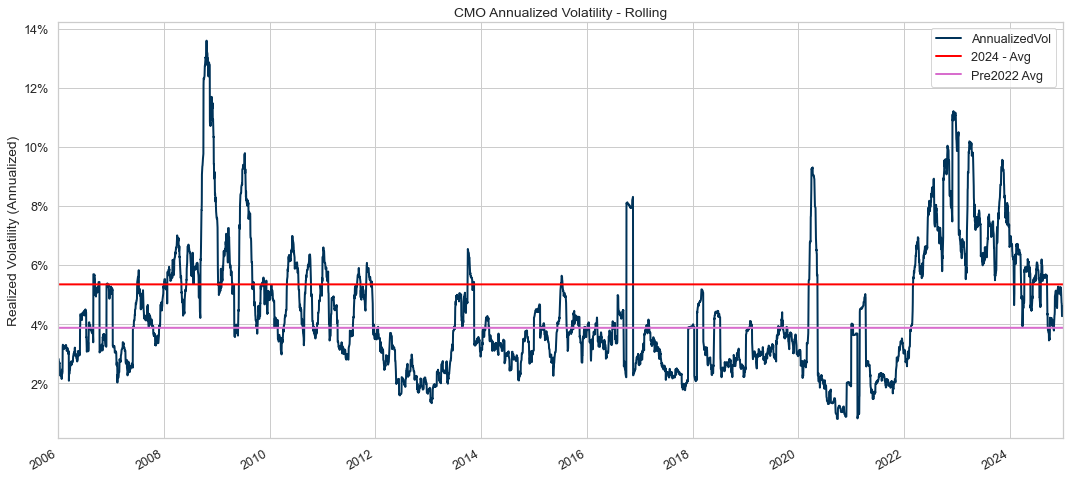

In [27]:
sample_start = '2006-01-01'  #sample_range[0][0]
sample_end = '2024-12-31'
ticker = "CMOS"
title = "CMO Annualized Volatility - Rolling"   

v = VarData(tickers = ticker)
df = v.wtd_log_return.copy()
df["AnnualizedVol"] = df["Wtd_Log_Return"].rolling(window = 30).std()* np.sqrt(252)  # Annualizing
df = df.dropna()
df["2024 - Avg"] = df.loc["2024-01-01":, "AnnualizedVol"].mean()


v = VarData(tickers = ticker)
df = v.wtd_log_return.copy()
df["AnnualizedVol"] = df["Wtd_Log_Return"].rolling(window = 30).std()* np.sqrt(252)  # Annualizing
df = df.dropna()
df["2024 - Avg"] = df.loc["2024-01-01":, "AnnualizedVol"].mean()
df["Pre2022 Avg"] = df.loc[:"2021-12-31":, "AnnualizedVol"].mean()


ax = df[["AnnualizedVol", "2024 - Avg", "Pre2022 Avg"]].plot(color = ["#003359", "red", "#D86DCD"], figsize=(18, 8.5), linewidth = 2) #uncomment when 4 index tickers specified above

ax.set(title = f"{title}") #uncomment for pass thru mbs

plt.ylabel("Realized Volatility (Annualized)")
plt.xlabel("")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(xmax = 1.0, decimals=0))
ax.set_xlim(sample_start, sample_end)

(13149.0, 20088.0)

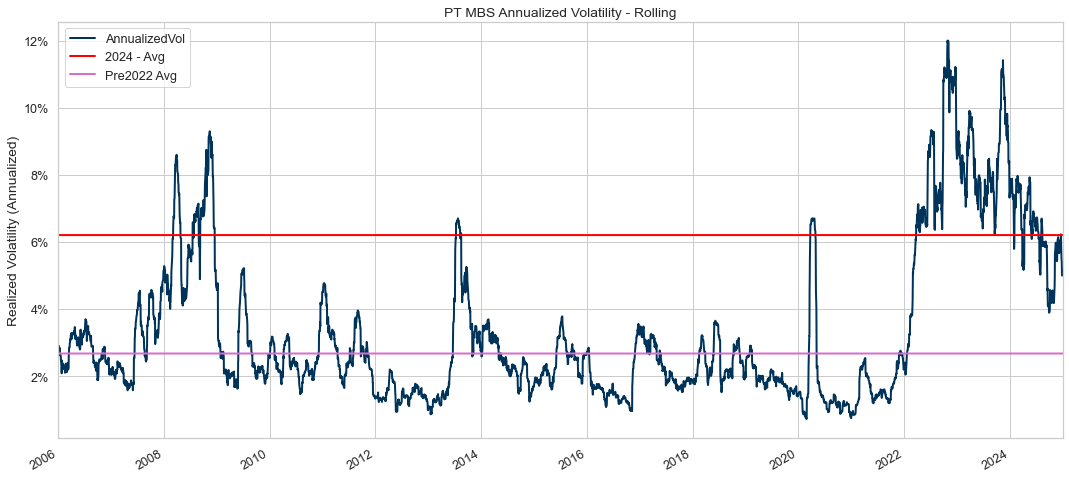

In [28]:
sample_start = '2006-01-01'  #sample_range[0][0]
sample_end = '2024-12-31'
ticker = "M0A0"
title = "PT MBS Annualized Volatility - Rolling"   

v = VarData(tickers = ticker)
df = v.wtd_log_return.copy()
df["AnnualizedVol"] = df["Wtd_Log_Return"].rolling(window = 30).std()* np.sqrt(252)  # Annualizing
df = df.dropna()
df["2024 - Avg"] = df.loc["2024-01-01":, "AnnualizedVol"].mean()


v = VarData(tickers = ticker)
df = v.wtd_log_return.copy()
df["AnnualizedVol"] = df["Wtd_Log_Return"].rolling(window = 30).std()* np.sqrt(252)  # Annualizing
df = df.dropna()
df["2024 - Avg"] = df.loc["2024-01-01":, "AnnualizedVol"].mean()
df["Pre2022 Avg"] = df.loc[:"2021-12-31":, "AnnualizedVol"].mean()


ax = df[["AnnualizedVol", "2024 - Avg", "Pre2022 Avg"]].plot(color = ["#003359", "red", "#D86DCD"], figsize=(18, 8.5), linewidth = 2) #uncomment when 4 index tickers specified above

ax.set(title = f"{title}") #uncomment for pass thru mbs

plt.ylabel("Realized Volatility (Annualized)")
plt.xlabel("")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(xmax = 1.0, decimals=0))
ax.set_xlim(sample_start, sample_end)

In [29]:
2/3

0.6666666666666666

In [32]:
3.4/4-1

-0.15000000000000002